# Figure 3: VAE recovery against training-set size

Section 4.3, `fig:training_sizes`. Holdout reconstruction quality along the
training-size ladder, mean and spread over seeds, with the adopted size
marked. Ported from `VAE_PaperFigures.ipynb` F4_training_size, which reads
the ladder's `summary.csv`; the paper map's legacy name for this row is
`vae_training_low_res`, and F4 is the surviving implementation of it.


## Imports

In [1]:
from _setup import *


## Setup

The ladder summary: one row per (n_train, seed), evaluated on the holdout.
NTRAIN_N is the adopted size, the one the shipped VAE_TAG was trained at.


In [2]:
NTRAIN_SUMMARY = os.path.join(REPO, '..', 'Sydney', 'FromScratch',
                              'vae_ntrain_winner', 'summary.csv')
NTRAIN_N = 640_000         # the adopted training size; VAE_TAG names it

# The draft's caption for fig:training_sizes names these three panels; the
# ladder's PR-AUC lives in the summary too if it is ever wanted back.
PANELS = (('aa_ssim_median', 'AA-SSIM', False),
          ('rmse_coeff_median', 'Coefficient RMSE', True),
          ('best_val_loss', 'Validation Loss', False))


## Loading

In [3]:
s = pd.read_csv(NTRAIN_SUMMARY).drop_duplicates(['n_train', 'seed'],
                                                keep='last')
g = s.groupby('n_train').agg(
    **{f'{c}_m': (c, 'mean') for c, _, _ in PANELS},
    **{f'{c}_s': (c, 'std') for c, _, _ in PANELS},
    seeds=('seed', 'nunique')).reset_index()
print(f'{len(s)} runs over {len(g)} ladder sizes, '
      f'{g.seeds.min()} to {g.seeds.max()} seeds each')


54 runs over 24 ladder sizes, 1 to 3 seeds each


## The figure

Text(0.5, 0, 'Training-Set Size')

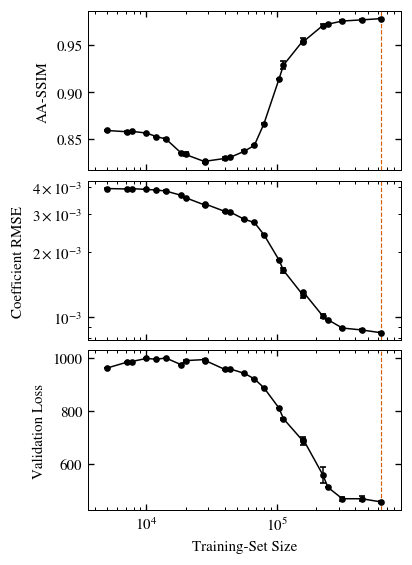

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(COL, 4.6), sharex=True)
for ax, (col, name, logy) in zip(axes, PANELS):
    ax.errorbar(g.n_train, g[f'{col}_m'], yerr=g[f'{col}_s'].fillna(0),
                marker='o', ms=3, capsize=2, lw=0.9, color='black')
    ax.set_xscale('log')
    if logy:
        ax.set_yscale('log')
    ax.axvline(NTRAIN_N, color=RED, lw=0.7, ls='--')
    ax.set_ylabel(name)
axes[0].set_xlim(g.n_train.min() / 1.4, g.n_train.max() * 1.4)
axes[-1].set_xlabel('Training-Set Size')


## Saving and caption numbers

In [5]:
save_fig(fig, 'fig03_training_sizes')
lo, hi = int(g.n_train.min()), int(g.n_train.max())
row = {int(r.n_train): r for r in g.itertuples()}
print(f'ladder {lo} to {hi} over {len(g)} sizes; adopted {NTRAIN_N}')
for col, name, _ in PANELS:
    a, b = row[lo], row[hi]
    print(f'{name}: {getattr(a, col + "_m"):.4f} at {lo} -> '
          f'{getattr(b, col + "_m"):.4f} at {hi}')
half = row[320_000]
full = row[NTRAIN_N]
print(f'gain from doubling 320000 -> {NTRAIN_N}: AA-SSIM '
      f'{full.aa_ssim_median_m - half.aa_ssim_median_m:+.4f}, val loss '
      f'{full.best_val_loss_m - half.best_val_loss_m:+.1f}')
vl = g.set_index('n_train').best_val_loss_m
print(f'validation loss: {vl.iloc[0]:.0f} at {vl.index[0]}, peak '
      f'{vl.max():.0f} at {vl.idxmax()}, {vl.iloc[-1]:.0f} at '
      f'{vl.index[-1]} (the early rise is the beta-ramp interaction '
      f'the draft describes)')
print(f'seed spread at {NTRAIN_N}: AA-SSIM s.d. '
      f'{full.aa_ssim_median_s:.4f} over {int(full.seeds)} seeds')


wrote notebooks/paper/figs/fig03_training_sizes.pdf, notebooks/paper/figs/fig03_training_sizes.png
ladder 5000 to 640000 over 24 sizes; adopted 640000
AA-SSIM: 0.8591 at 5000 -> 0.9783 at 640000
Coefficient RMSE: 0.0039 at 5000 -> 0.0008 at 640000
Validation Loss: 962.7540 at 5000 -> 453.9813 at 640000
gain from doubling 320000 -> 640000: AA-SSIM +0.0026, val loss -12.5
validation loss: 963 at 5000, peak 1001 at 14142, 454 at 640000 (the early rise is the beta-ramp interaction the draft describes)
seed spread at 640000: AA-SSIM s.d. 0.0004 over 3 seeds
